In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV, LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from geopy.distance import geodesic

In [4]:
df_train = pd.read_csv(r"C:\Users\marti\OneDrive\Boston University Classes\DX799 - DS Capstone - Fall 2026\Datasets for capstone\fraudTrain.csv", sep=",")

df_test = pd.read_csv(r"C:\Users\marti\OneDrive\Boston University Classes\DX799 - DS Capstone - Fall 2026\Datasets for capstone\fraudTest.csv", sep=",")

df = pd.concat((df_train, df_test), axis=0)


## EDA

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1852394 entries, 0 to 555718
Data columns (total 34 columns):
 #   Column                     Dtype         
---  ------                     -----         
 0   trans_date_trans_time      datetime64[ns]
 1   cc_num                     int64         
 2   merchant                   object        
 3   category                   object        
 4   amt                        float64       
 5   first                      object        
 6   last                       object        
 7   gender                     object        
 8   city                       object        
 9   state                      object        
 10  zip                        int64         
 11  lat                        float64       
 12  long                       float64       
 13  city_pop                   int64         
 14  job                        object        
 15  dob                        datetime64[ns]
 16  trans_num                  object        


In [83]:
df.shape

(1852394, 34)

In [7]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [8]:
df["is_fraud"].value_counts()

is_fraud
0    1842743
1       9651
Name: count, dtype: int64

In [ ]:
# Gets percentage rather than numbers above
df["is_fraud"].value_counts(normalize = True) * 100

is_fraud
0    99.478999
1     0.521001
Name: proportion, dtype: float64

<Axes: xlabel='is_fraud'>

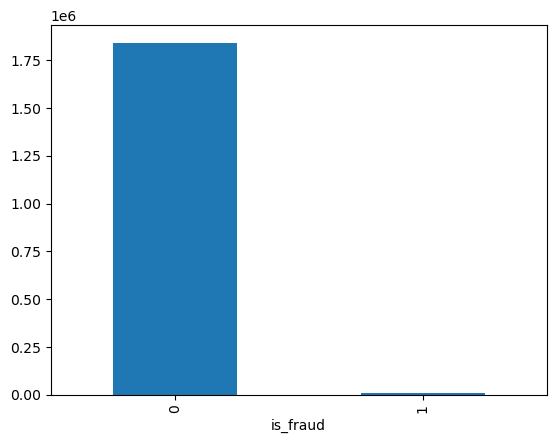

In [9]:
df["is_fraud"].value_counts().plot(kind="bar")

In [85]:
df.isnull().sum()

trans_date_trans_time        0
cc_num                       0
merchant                     0
category                     0
amt                          0
first                        0
last                         0
gender                       0
city                         0
state                        0
zip                          0
lat                          0
long                         0
city_pop                     0
job                          0
dob                          0
trans_num                    0
unix_time                    0
merch_lat                    0
merch_long                   0
is_fraud                     0
hour                         0
distance                     0
age                          0
gender_M                     0
age_distance_interact        0
gender_distance_interact     0
citypop_distnace_interact    0
age_sq                       0
distance_sq                  0
city_pop_sq                  0
age_c                        0
distance

In [87]:
df.duplicated().sum()

0

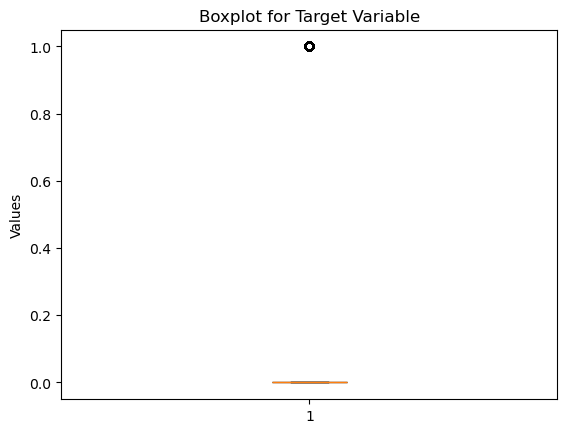

In [10]:
plt.boxplot(df["is_fraud"], vert = True, patch_artist = True)
plt.title("Boxplot for Target Variable")
plt.ylabel("Values")
plt.show()

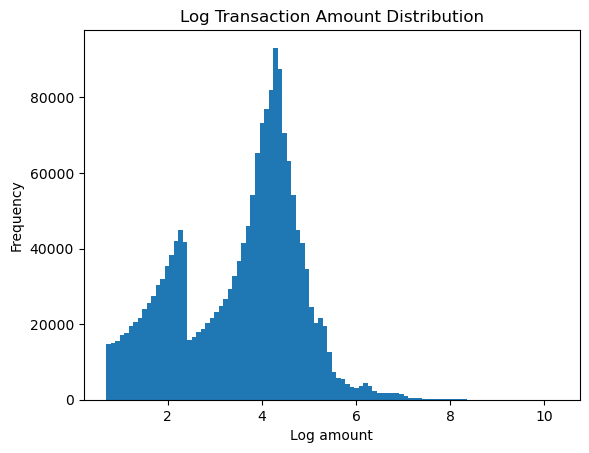

In [11]:
plt.hist(np.log1p(df["amt"]), bins=100)
plt.title("Log Transaction Amount Distribution")
plt.xlabel("Log amount")
plt.ylabel("Frequency")
plt.show()


In [12]:
# Drop cols won't really need

drop_cols = ["Unnamed: 0", "street"]

df = df.drop(columns=drop_cols)

In [13]:
## feature engineering (clearing it up a bit) ##
# Transaction hour - fraud spikes at certain times?
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df["hour"] = df["trans_date_trans_time"].dt.hour

# Distance - Large purchases that are far away from the customer may increase the chance it's fraud.
# (Client lives in NY but transaction in TX)

df["distance"] = df.apply(
    lambda row:geodesic(
        (row["lat"], row["long"]),
        (row["merch_lat"], row["merch_long"])
    ).miles,
    axis=1
)


In [14]:
df["distance"].describe()

count    1.852394e+06
mean     4.729229e+01
std      1.807738e+01
min      1.384012e-02
25%      3.438791e+01
50%      4.862119e+01
75%      6.118769e+01
max      9.436652e+01
Name: distance, dtype: float64

In [15]:
df["hour"].describe()

count    1.852394e+06
mean     1.280612e+01
std      6.815753e+00
min      0.000000e+00
25%      7.000000e+00
50%      1.400000e+01
75%      1.900000e+01
max      2.300000e+01
Name: hour, dtype: float64

In [16]:
df["trans_date_trans_time"].describe()

count                          1852394
mean     2020-01-20 21:31:46.801827328
min                2019-01-01 00:00:18
25%      2019-07-23 04:13:43.750000128
50%                2020-01-02 01:15:31
75%      2020-07-23 12:11:25.249999872
max                2020-12-31 23:59:34
Name: trans_date_trans_time, dtype: object

In [17]:
## feature engineering cont.

df["dob"] = pd.to_datetime(df["dob"])
current_year = 2026
df["age"] = current_year - df["dob"].dt.year
df["gender_M"] = (df["gender"] == "M").astype(int)

In [18]:
df["dob"].describe()

count                          1852394
mean     1973-10-15 11:05:05.744458256
min                1924-10-30 00:00:00
25%                1962-08-13 00:00:00
50%                1975-11-30 00:00:00
75%                1987-04-23 00:00:00
max                2005-01-29 00:00:00
Name: dob, dtype: object

In [19]:
df["age"].describe()

count    1.852394e+06
mean     5.271065e+01
std      1.739057e+01
min      2.100000e+01
25%      3.900000e+01
50%      5.100000e+01
75%      6.400000e+01
max      1.020000e+02
Name: age, dtype: float64

In [ ]:
# Discover imbalances
df.groupby("is_fraud")["amt"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1842743.0,67.651278,153.548108,1.00,9.610,47.24,82.560,28948.90
1,9651.0,530.661412,391.028873,1.06,240.075,390.00,902.365,1376.04


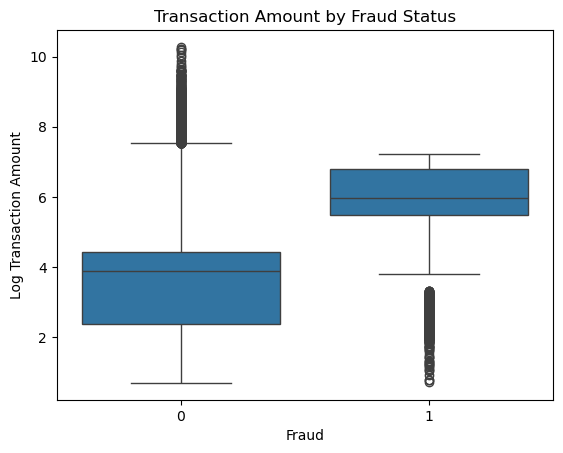

In [91]:
sns.boxplot(
    data = df,
    x = "is_fraud",
    y = np.log1p(df["amt"]))
plt.xlabel("Fraud")
plt.ylabel("Log Transaction Amount")
plt.title("Transaction Amount by Fraud Status")
plt.show()

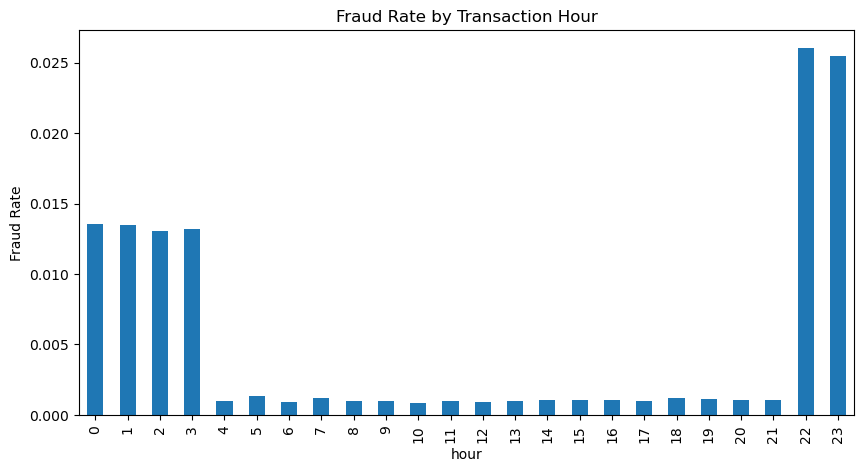

In [81]:
fraud_by_hour = df.groupby("hour")["is_fraud"].mean()

fraud_by_hour.plot(
    kind = "bar",
    figsize = (10,5)
)
plt.ylabel("Fraud Rate")
plt.title("Fraud Rate by Transaction Hour")
plt.show()

In [82]:
df.groupby("is_fraud")["distance"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1842743.0,47.291814,18.078200,0.013840,34.387278,48.621443,61.188213,94.366525
1,9651.0,47.382628,17.921823,0.458464,34.550285,48.543819,61.114260,89.698594


## 1.2 Activity: Week 1 Jupyter Notebook – Linear Regression 1

In [20]:
## Implement interaction terms

df["age_distance_interact"] = (df["age"] * df["distance"])
df["gender_distance_interact"] = (df["gender_M"] * df["distance"])
df["citypop_distnace_interact"] = (df["city_pop"] * df['distance'])

In [21]:
## polynomial terms
df["age_sq"] = df["age"] ** 2
df["distance_sq"] = df["distance"] ** 2
df["city_pop_sq"] = df["city_pop"] ** 2

Squared Amount since fraud risk may increase exponentially at a larger transaction amount rather than a smaller amount.

In [22]:
df.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,city,state,...,hour,distance,age,gender_M,age_distance_interact,gender_distance_interact,citypop_distnace_interact,age_sq,distance_sq,city_pop_sq
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,Moravian Falls,NC,...,0,48.947783,38,0,1860.015751,0.000000,171072.501301,1444,2395.885453,12215025
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,Orient,WA,...,0,18.775736,48,0,901.235338,0.000000,2797.584695,2304,352.528270,22201
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,Malad City,ID,...,0,67.172035,64,1,4299.010249,67.172035,279032.633950,4096,4512.082304,17255716
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,Boulder,MT,...,0,59.455974,59,1,3507.902483,59.455974,115285.134134,3481,3535.012878,3759721
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,Doe Hill,VA,...,0,48.282030,40,1,1931.281197,48.282030,4779.920962,1600,2331.154413,9801


In [23]:
y = df["amt"]
X = df[["city_pop", "distance", "age", "age_distance_interact", "distance_sq", "age_sq", "gender_distance_interact", "is_fraud", "category"]]

#  convert the categoricals to dummy variables
X = pd.get_dummies(X, drop_first=True)
X = X.astype(float)

X.head()

,city_pop,distance,age,age_distance_interact,distance_sq,age_sq,gender_distance_interact,is_fraud,category_food_dining,category_gas_transport,...,category_grocery_pos,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel
0,3495.0,48.947783,38.0,1860.015751,2395.885453,1444.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,149.0,18.775736,48.0,901.235338,352.528270,2304.0,0.000000,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4154.0,67.172035,64.0,4299.010249,4512.082304,4096.0,67.172035,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1939.0,59.455974,59.0,3507.902483,3535.012878,3481.0,59.455974,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,99.0,48.282030,40.0,1931.281197,2331.154413,1600.0,48.282030,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [24]:
# Use stats models as it's better later on for VIF

### Linear Regression

In [25]:
X.dtypes.value_counts()

float64    21
Name: count, dtype: int64

In [26]:
# after dropping X values - rerun VIF

# X = X.drop(columns=["long", "lat", "merch_long", "merch_lat"],           errors = "ignore")

## Detect Multicollinearity 
vif_data = pd.DataFrame()

vif_data["Feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor( X.values, i)
                   for i in range(X.shape[1])]

vif_data = vif_data.sort_values(
    by = "VIF",
    ascending = False
)

print(vif_data.head(20))

                     Feature         VIF
1                   distance  137.439418
2                        age  121.351011
5                     age_sq   64.539397
4                distance_sq   59.204079
3      age_distance_interact   52.307187
9     category_gas_transport    2.302820
11      category_grocery_pos    2.235012
13             category_home    2.226558
19     category_shopping_pos    2.153052
14        category_kids_pets    2.125860
18     category_shopping_net    1.967038
17    category_personal_care    1.904546
8       category_food_dining    1.899219
12   category_health_fitness    1.847273
6   gender_distance_interact    1.828263
16         category_misc_pos    1.787504
15         category_misc_net    1.626956
10      category_grocery_net    1.447646
20           category_travel    1.402198
0                   city_pop    1.095843


From the VIF we see distance and age have an extremely high results multicollinearity.

In [27]:
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    amt   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     5443.
Date:                Fri, 02 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:32:20   Log-Likelihood:            -1.1966e+07
No. Observations:             1852394   AIC:                         2.393e+07
Df Residuals:                 1852372   BIC:                         2.393e+07
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

- Used VIF to asses multicollinearity. Geographic coordinate features (long, lat, etc) showed extremely high VIF values to which I did replace with a distance feature. Remaining predictors showed acceptable VIF levels.

- The selected features explain a small portion of transaction amount varability. Suggesting that spending behavior is influenced by additional factors not included in the model.

- Fraudlent transactions are associated with roughlt $451 higher transaction amounts. 

- Distance between customer and merchant locations did now show a statisitcally signifciant relationship with the transaction amount. 

- However, travle and grocery sale transactions were associated with larger transaction amounts relative to the ommited categories. 

# Redo interaction and polynomial terms as they are highly corelated 

In [28]:
## Center variables 
df["age_c"] = df["age"] - df["age"].mean()
df["distance_c"] = df["distance"] - df["distance"].mean()
df["city_pop_c"] = df["city_pop"] - df["city_pop"].mean()

## Recreate Terms
df["age_distance_interact"] = (df["age_c"] * df["distance_c"])

df["age_sq"] = df["age_c"] ** 2
df["distance_sq"] = df["distance_c"] ** 2
df["city_pop_sq"] = df["city_pop_c"] ** 2

In [29]:
y = df["amt"] 
X = df[["city_pop", "distance", "age", "age_distance_interact", "distance_sq", "age_sq", "gender_distance_interact", "is_fraud", "category"]]

X = pd.get_dummies(X, drop_first=True)
X = X.astype(float)

vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values(
    by = "VIF",
    ascending = False
))

                     Feature       VIF
2                        age  9.278968
1                   distance  6.998552
5                     age_sq  1.925686
9     category_gas_transport  1.841089
6   gender_distance_interact  1.827967
11      category_grocery_pos  1.784061
13             category_home  1.775077
14        category_kids_pets  1.717719
19     category_shopping_pos  1.711821
4                distance_sq  1.694378
18     category_shopping_net  1.595735
17    category_personal_care  1.575658
8       category_food_dining  1.552488
12   category_health_fitness  1.528399
16         category_misc_pos  1.477187
15         category_misc_net  1.393012
20           category_travel  1.260872
10      category_grocery_net  1.249355
0                   city_pop  1.087922
7                   is_fraud  1.009974
3      age_distance_interact  1.000055


In [30]:
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    amt   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     5443.
Date:                Fri, 02 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:35:22   Log-Likelihood:            -1.1966e+07
No. Observations:             1852394   AIC:                         2.393e+07
Df Residuals:                 1852372   BIC:                         2.393e+07
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

# Week 2.2 Activiy - Linear Regression 2

In [31]:
# from sklearn.linear_model import Ridge, Lasso, ElasticNet
# from sklearn.preprocessing import StandardScaler

# from sklearn.metrics import mean_squared_error, r2_score


In [32]:
train_n = df_train.shape[0]

X_train = X.iloc[:train_n]
X_test = X.iloc[train_n:]

y_train = y.iloc[:train_n]
y_test = y.iloc[train_n:]

In [33]:
X_train.head()

,const,city_pop,distance,age,age_distance_interact,distance_sq,age_sq,gender_distance_interact,is_fraud,category_food_dining,...,category_grocery_pos,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel
0,1.0,3495.0,48.947783,38.0,-24.353427,2.740667,216.403306,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,1.0,149.0,18.775736,48.0,134.331570,813.193663,22.190250,0.000000,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,4154.0,67.172035,64.0,224.429380,395.204390,127.449360,67.172035,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,1939.0,59.455974,59.0,76.501653,147.955291,39.555888,59.455974,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,99.0,48.282030,40.0,-12.580280,0.979591,161.560695,48.282030,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [34]:
scale = StandardScaler()

X_train_scaled = scale.fit_transform(X_train)
X_test_scaled = scale.transform(X_test)

In [35]:
# Lasso regression

lasso_reg = Lasso(alpha = 10, max_iter = 10000)
lasso_reg.fit(X_train_scaled, y_train)

lasso_pred = lasso_reg.predict(X_test_scaled)

mse = mean_squared_error(y_test, lasso_pred)
r2 = r2_score(y_test, lasso_pred)

print("Lasso RMSE:", np.sqrt(mse))
print("Lasso R2:", r2)

Lasso RMSE: 153.99573169298156
Lasso R2: 0.034781716247486716


In [36]:
lasso_reg2 = Lasso(alpha = 0.1, max_iter = 10000)
lasso_reg2.fit(X_train_scaled, y_train)

lasso_pred2 = lasso_reg2.predict(X_test_scaled)

mse = mean_squared_error(y_test, lasso_pred2)
r2 = r2_score(y_test, lasso_pred2)

print("Lasso RMSE:", np.sqrt(mse))
print("Lasso R2:", r2)

Lasso RMSE: 152.93317872257276
Lasso R2: 0.04805555568614728


In [37]:
# Ridge Regression

ridge_reg = Ridge(alpha=10)
ridge_reg.fit(X_train_scaled, y_train)

ridge_pred = ridge_reg.predict(X_test_scaled)

mse = mean_squared_error(y_test, ridge_pred)
r2 = r2_score(y_test, ridge_pred)

print("Ridge RMSE:", np.sqrt(mse))
print("Ridge R2:", r2)

Ridge RMSE: 152.93334674974722
Ridge R2: 0.04805346388861309


In [38]:
ridge_reg2 = Ridge(alpha=0.1)
ridge_reg2.fit(X_train_scaled, y_train)

ridge_pred2 = ridge_reg2.predict(X_test_scaled)

mse = mean_squared_error(y_test, ridge_pred2)
r2 = r2_score(y_test, ridge_pred2)

print("Ridge RMSE:", np.sqrt(mse))
print("Ridge R2:", r2)

Ridge RMSE: 152.93334692412083
Ridge R2: 0.048053461717806445


In [39]:
## Elastic Net regression

elastic_reg = ElasticNet(alpha=10, l1_ratio = 0.5, max_iter = 10000)
elastic_reg.fit(X_train_scaled, y_train)

elastic_pred = elastic_reg.predict(X_test_scaled)

mse = mean_squared_error(y_test, elastic_pred)
r2 = r2_score(y_test, elastic_pred)

print("Elastic RMSE:", np.sqrt(mse))
print("Elastic R^2:", r2)

Elastic RMSE: 155.8761412304296
Elastic R^2: 0.011065643432810801


In [40]:
elastic_reg2 = ElasticNet(alpha=0.1, l1_ratio = 0.5, max_iter = 10000)
elastic_reg2.fit(X_train_scaled, y_train)

elastic_pred2 = elastic_reg2.predict(X_test_scaled)

mse = mean_squared_error(y_test, elastic_pred2)
r2 = r2_score(y_test, elastic_pred2)

print("Elastic RMSE:", np.sqrt(mse))
print("Elastic R^2:", r2)

Elastic RMSE: 152.94126664071933
Elastic R^2: 0.04795486527483728


In [41]:
# comparios table
print("Comparison Table with Alpha = 10")
res1 = pd.DataFrame({
    "Model": ["Lasso", "Ridge", "Elastic Net"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lasso_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred)),
        np.sqrt(mean_squared_error(y_test, elastic_pred))
    ],
    "R2": [
        r2_score(y_test, lasso_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, elastic_pred)
    ]
})
res1

Comparison Table with Alpha = 10


,Model,RMSE,R2
0,Lasso,153.995732,0.034782
1,Ridge,152.933347,0.048053
2,Elastic Net,155.876141,0.011066


In [42]:
print("Comparison Table with Alpha = 0.1")
res2 = pd.DataFrame({
    "Model": ["Lasso", "Ridge", "Elastic Net"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lasso_pred2)),
        np.sqrt(mean_squared_error(y_test, ridge_pred2)),
        np.sqrt(mean_squared_error(y_test, elastic_pred2))
    ],
    "R2": [
        r2_score(y_test, lasso_pred2),
        r2_score(y_test, ridge_pred2),
        r2_score(y_test, elastic_pred2)
    ]
})
res2

Comparison Table with Alpha = 0.1


,Model,RMSE,R2
0,Lasso,152.933179,0.048056
1,Ridge,152.933347,0.048053
2,Elastic Net,152.941267,0.047955


Ridge, Lasso, and Elastic Net regression models had similar results with an RMSE about 152.96 and an R^2 of 0.0477. Meaning the models explain around 4.8% of the variation in transaction amount. 

Elastic Net model did not outperform either Ridge or Lasso models, suggesting that combining the L1 and L2 regularization did not improve the predictive power of the model.

### Week 3 — Forward & Backward Selection, PCR, PLSR

In [43]:
# from sklearn.feature_selection import SequentialFeatureSelector

#### Forward Selection

In [44]:
lr = LinearRegression()

forward_selection = SequentialFeatureSelector(
    lr, 
    n_features_to_select='auto',
    direction='forward',
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

forward_selection.fit(X_train, y_train)
forward_features = X_train.columns[forward_selection.get_support()]
print(forward_features)

c:\Users\marti\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Index(['age', 'is_fraud', 'category_food_dining', 'category_grocery_net',
       'category_grocery_pos', 'category_health_fitness', 'category_misc_net',
       'category_personal_care', 'category_shopping_net',
       'category_shopping_pos', 'category_travel'],
      dtype='object')


In [45]:
# Fit the forward model

lr_forward = LinearRegression()

lr_forward.fit(
    X_train[forward_features],
    y_train
)

forward_pred = lr_forward.predict(X_test[forward_features])

# evaluate the model
forward_rmse = np.sqrt(mean_squared_error(y_test, forward_pred))
forward_r2 = r2_score(y_test, forward_pred)

print("Forward Selection RMSE:", forward_rmse)
print("Forward Selection R^2:", forward_r2)

Forward Selection RMSE: 152.94772408634896
Forward Selection R^2: 0.047874469582890655


#### Backward Selection 

In [46]:
backward_selection = SequentialFeatureSelector(
    lr, 
    n_features_to_select='auto',
    direction='backward',
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs = -1
)

backward_selection.fit(X_train, y_train)
backward_features = X_train.columns[backward_selection.get_support()]

print(backward_features)

Index(['age', 'is_fraud', 'category_food_dining', 'category_grocery_net',
       'category_grocery_pos', 'category_health_fitness', 'category_misc_net',
       'category_personal_care', 'category_shopping_net',
       'category_shopping_pos', 'category_travel'],
      dtype='object')


In [47]:
lr_backward = LinearRegression()

lr_backward.fit(
    X_train[backward_features], y_train)

backward_pred = lr_backward.predict(X_test[backward_features])

backward_rmse = np.sqrt(mean_squared_error(y_test, backward_pred))
backward_r2 = r2_score(y_test, backward_pred)

print("Backward Selection RMSE", backward_rmse)
print("Backward R^2 Score:", backward_r2)

Backward Selection RMSE 152.94772408634896
Backward R^2 Score: 0.047874469582890655


### Principal Component Regresion (PCR)

In [48]:
pcr = make_pipeline(
    StandardScaler(),
    PCA(n_components=8),
    LinearRegression()
)

pcr.fit(X_train, y_train)
pca = pcr.named_steps["pca"]

pcr_pred = pcr.predict(X_test)

pcr_rmse = np.sqrt(mean_squared_error(y_test, pcr_pred))
pcr_r2 = r2_score(y_test, pcr_pred)

print("PCR RMSE:", pcr_rmse)
print("PCR R^2 Score:", pcr_r2)
print("__________________")
print("Total Variance", pca.explained_variance_ratio_.sum())

PCR RMSE: 154.54116650780898
PCR R^2 Score: 0.027932227806208076
__________________
Total Variance 0.45361490423693474


#### PLSR

In [49]:
pls = make_pipeline(
    StandardScaler(),
    PLSRegression(n_components=10)
)
pls.fit(X_train, y_train)
pls_pred = pls.predict(X_test)
pls_rmse = np.sqrt(mean_squared_error(y_test, pls_pred))
pls_r2 = r2_score(y_test, pls_pred)

print("PLSR RMSE:", pls_rmse)
print("PLSR R^2 Score:", pls_r2)

PLSR RMSE: 152.93334692789563
PLSR R^2 Score: 0.04805346167081326


PLSR and Elastic Net is almost identical. While PLSR sleects componentes tht max covariance between predictors and the response varialbe. Whereas PCR selects components based soley on predictor variance. 

## Week 4 - Logisitc Regression and Feature Scaling

In [50]:
print(df.head()) 

  trans_date_trans_time            cc_num                            merchant  \
0   2019-01-01 00:00:18  2703186189652095          fraud_Rippin, Kub and Mann   
1   2019-01-01 00:00:44      630423337322     fraud_Heller, Gutmann and Zieme   
2   2019-01-01 00:00:51    38859492057661                fraud_Lind-Buckridge   
3   2019-01-01 00:01:16  3534093764340240  fraud_Kutch, Hermiston and Farrell   
4   2019-01-01 00:03:06   375534208663984                 fraud_Keeling-Crist   

        category     amt      first     last gender            city state  \
0       misc_net    4.97   Jennifer    Banks      F  Moravian Falls    NC   
1    grocery_pos  107.23  Stephanie     Gill      F          Orient    WA   
2  entertainment  220.11     Edward  Sanchez      M      Malad City    ID   
3  gas_transport   45.00     Jeremy    White      M         Boulder    MT   
4       misc_pos   41.96      Tyler   Garcia      M        Doe Hill    VA   

   ...  gender_M  age_distance_interact  gender_di

In [51]:
X = df.drop(columns=["is_fraud"])
y = df["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size = 0.2,
)

In [52]:
X_train.dtypes[X_train.dtypes == "datetime64[ns]"]

trans_date_trans_time    datetime64[ns]
dob                      datetime64[ns]
dtype: object

In [53]:
X_train = X_train.drop(columns=["trans_date_trans_time", "dob"])
X_test = X_test.drop(columns=["trans_date_trans_time", "dob"])

In [54]:
X_train.dtypes

cc_num                         int64
merchant                      object
category                      object
amt                          float64
first                         object
last                          object
gender                        object
city                          object
state                         object
zip                            int64
lat                          float64
long                         float64
city_pop                       int64
job                           object
trans_num                     object
unix_time                      int64
merch_lat                    float64
merch_long                   float64
hour                           int32
distance                     float64
age                            int32
gender_M                       int32
age_distance_interact        float64
gender_distance_interact     float64
citypop_distnace_interact    float64
age_sq                       float64
distance_sq                  float64
c

In [55]:
# keep category and state

keep = ["category", "state"]

X_train = pd.get_dummies(
    X_train, 
    columns = keep,
    drop_first = True
)

X_test = pd.get_dummies(
    X_test, 
    columns = keep,
    drop_first = True
)

# drop remaining
obj_cols = X_train.select_dtypes(include=["object"]).columns

X_train = X_train.drop(columns = obj_cols)
X_test = X_test.drop(columns=obj_cols)

X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)# need to align so the dummy varibles match

In [56]:
X_train.select_dtypes(exclude=["number"]).columns

Index(['category_food_dining', 'category_gas_transport',
       'category_grocery_net', 'category_grocery_pos',
       'category_health_fitness', 'category_home', 'category_kids_pets',
       'category_misc_net', 'category_misc_pos', 'category_personal_care',
       'category_shopping_net', 'category_shopping_pos', 'category_travel',
       'state_AL', 'state_AR', 'state_AZ', 'state_CA', 'state_CO', 'state_CT',
       'state_DC', 'state_DE', 'state_FL', 'state_GA', 'state_HI', 'state_IA',
       'state_ID', 'state_IL', 'state_IN', 'state_KS', 'state_KY', 'state_LA',
       'state_MA', 'state_MD', 'state_ME', 'state_MI', 'state_MN', 'state_MO',
       'state_MS', 'state_MT', 'state_NC', 'state_ND', 'state_NE', 'state_NH',
       'state_NJ', 'state_NM', 'state_NV', 'state_NY', 'state_OH', 'state_OK',
       'state_OR', 'state_PA', 'state_RI', 'state_SC', 'state_SD', 'state_TN',
       'state_TX', 'state_UT', 'state_VA', 'state_VT', 'state_WA', 'state_WI',
       'state_WV', 'state_WY'],


In [57]:
X_train

,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,hour,...,state_SD,state_TN,state_TX,state_UT,state_VA,state_VT,state_WA,state_WI,state_WV,state_WY
691074,375082648741747,54.10,56546,47.0999,-96.7270,346,1350836360,47.946073,-96.616903,16,...,False,False,False,False,False,False,False,False,False,False
93012,4225990116481262579,30.97,96727,20.0827,-155.4880,4878,1330111714,19.252655,-156.296780,19,...,False,False,False,False,False,False,False,False,False,False
749967,3585052663373890,48.07,13484,42.8546,-75.6605,176,1353129084,43.233353,-75.659684,5,...,False,False,False,False,False,False,False,False,False,False
1239332,3585740823295298,58.42,79252,34.2956,-99.7494,3202,1370055948,33.612441,-100.275637,3,...,False,False,True,False,False,False,False,False,False,False
1198321,6011626928491360,77.51,38315,35.2289,-88.6440,3876,1368678631,35.487668,-88.670114,4,...,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
940053,4956828990005111019,1.32,7208,40.6747,-74.2239,124967,1357820420,41.333962,-75.046736,12,...,False,False,False,False,False,False,False,False,False,False
79806,4584931703207308232,195.30,75218,32.8463,-96.6972,1263321,1329453721,33.759428,-97.087723,4,...,False,False,True,False,False,False,False,False,False,False
203262,213155997615567,92.60,15727,40.5503,-79.3237,168,1334408269,40.413872,-79.041639,12,...,False,False,False,False,False,False,False,False,False,False
396050,4822367783500458,66.64,33844,28.0758,-81.5929,33804,1385226137,28.870377,-81.468738,17,...,False,False,False,False,False,False,False,False,False,False


In [58]:
X_train = X_train.astype(float)
X_test = X_test.astype(float)

In [59]:
X_train

,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,hour,...,state_SD,state_TN,state_TX,state_UT,state_VA,state_VT,state_WA,state_WI,state_WV,state_WY
691074,3.750826e+14,54.10,56546.0,47.0999,-96.7270,346.0,1.350836e+09,47.946073,-96.616903,16.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
93012,4.225990e+18,30.97,96727.0,20.0827,-155.4880,4878.0,1.330112e+09,19.252655,-156.296780,19.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
749967,3.585053e+15,48.07,13484.0,42.8546,-75.6605,176.0,1.353129e+09,43.233353,-75.659684,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1239332,3.585741e+15,58.42,79252.0,34.2956,-99.7494,3202.0,1.370056e+09,33.612441,-100.275637,3.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1198321,6.011627e+15,77.51,38315.0,35.2289,-88.6440,3876.0,1.368679e+09,35.487668,-88.670114,4.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
940053,4.956829e+18,1.32,7208.0,40.6747,-74.2239,124967.0,1.357820e+09,41.333962,-75.046736,12.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
79806,4.584932e+18,195.30,75218.0,32.8463,-96.6972,1263321.0,1.329454e+09,33.759428,-97.087723,4.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
203262,2.131560e+14,92.60,15727.0,40.5503,-79.3237,168.0,1.334408e+09,40.413872,-79.041639,12.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
396050,4.822368e+15,66.64,33844.0,28.0758,-81.5929,33804.0,1.385226e+09,28.870377,-81.468738,17.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [60]:
log_reg1 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter = 10000,
    )
)

log_reg1.fit(X_train, y_train)

logit_pred1 = log_reg1.predict(X_test)
logit_prob1 = log_reg1.predict_proba(X_test)[:,1]

In [61]:
print("Confusion Matrix\n", confusion_matrix(y_test, logit_pred1))
print()
print("Classification Report\n", classification_report(y_test, logit_pred1))
print()
print("ROC AUC Score:", roc_auc_score(y_test, logit_prob1))

Confusion Matrix
 [[368450    121]
 [  1901      7]]

Classification Report
               precision    recall  f1-score   support

           0       0.99      1.00      1.00    368571
           1       0.05      0.00      0.01      1908

    accuracy                           0.99    370479
   macro avg       0.52      0.50      0.50    370479
weighted avg       0.99      0.99      0.99    370479


ROC AUC Score: 0.8114473044391568


Feature scaling was involved with the pipeline. The scaler was fit on the training data and automatically applied to both training and testing data during model fitting and prediction.

### Cross validation k=5

In [62]:
log_reg2 = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(
        max_iter = 10000,
        cv = 5
    )
)

log_reg2.fit(X_train, y_train)
logit_pred2 = log_reg2.predict(X_test)
logit_prob2 = log_reg2.predict_proba(X_test)[:,1]


print("K-fold = 5\n")
print("\nConfusion Matrix\n", confusion_matrix(y_test, logit_pred2))
print()
print("classification Report\n", classification_report(y_test, logit_pred2))
print()
print("Roc AUC Score:", roc_auc_score(y_test, logit_prob2))


K-fold = 5


Confusion Matrix
 [[368456    115]
 [  1906      2]]

classification Report
               precision    recall  f1-score   support

           0       0.99      1.00      1.00    368571
           1       0.02      0.00      0.00      1908

    accuracy                           0.99    370479
   macro avg       0.51      0.50      0.50    370479
weighted avg       0.99      0.99      0.99    370479


Roc AUC Score: 0.8303366670825171


### Week 5 - Support Vector Machines 

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size = 0.2,
)

In [64]:
X_train_nums_only = X_train.select_dtypes(include=["int64", "float64", "bool"])
X_test_nums_only = X_test[X_train_nums_only.columns]

X_train_nums_only = X_train_nums_only.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

In [65]:
X_train_nums_only

,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,distance,age_distance_interact,gender_distance_interact,citypop_distnace_interact,age_sq,distance_sq,city_pop_sq,age_c,distance_c,city_pop_c
0,36913587729122,50.17,83646,43.6498,-116.4306,84106,1372490298,42.663836,-115.923574,72.726068,58.226756,0.000000,6.116699e+06,5.241111,646.877243,2.059049e+07,2.289347,25.433782,-4537.674509
1,4155021259183870,80.90,73559,34.7032,-98.9591,540,1385246790,35.584894,-98.030870,80.354188,-321.052640,0.000000,4.339126e+04,94.296778,1093.089285,7.762257e+09,-9.710653,33.061901,-88103.674509
2,4302480582202074,132.79,49440,43.2326,-86.2492,128715,1348417317,43.846605,-86.578043,45.492144,39.082268,45.492144,5.855521e+06,471.352445,3.240513,1.605711e+09,-21.710653,-1.800142,40071.325491
3,2254917871818484,2.16,20687,38.0828,-76.3477,313,1325508499,37.414598,-76.075861,48.428606,-3.080168,0.000000,1.515815e+04,7.347639,1.291222,7.802308e+09,-2.710653,1.136320,-88330.674509
4,6538891242532018,5.01,72476,36.0244,-90.9288,7155,1375641726,35.837329,-90.391959,32.749468,53.963352,0.000000,2.343224e+05,13.768944,211.493579,6.640404e+09,-3.710653,-14.542819,-81488.674509
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481910,3582754887089201,25.76,71960,34.4596,-93.6743,1383,1377854288,35.169625,-92.789723,70.174647,166.797468,70.174647,9.705154e+04,53.134582,523.602411,7.614425e+09,7.289347,22.882360,-87260.674509
1481911,6011893664860915,106.33,80120,39.5994,-105.0044,320420,1372258185,39.899429,-104.259482,44.745713,4.356303,0.000000,1.433742e+07,2.926333,6.485036,5.372027e+10,-1.710653,-2.546573,231776.325491
1481912,630469040731,5.11,97014,45.6710,-121.8686,1288,1335677791,46.403719,-120.943760,67.378506,749.001999,0.000000,8.678352e+04,1390.495414,403.456199,7.631014e+09,37.289347,20.086219,-87355.674509
1481913,3589289942931264,82.22,57374,43.7557,-97.5936,343,1378948815,43.927815,-97.534904,12.239454,-45.195272,0.000000,4.198133e+03,1.662416,1228.701092,7.797009e+09,1.289347,-35.052833,-88300.674509


In [66]:
svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C = 1,
        class_weight = "balanced",
        random_state = 42,
        max_iter = 10000
    )
)
svm_model.fit(X_train_nums_only, y_train)
svm_pred = svm_model.predict(X_test_nums_only)
# svm_prob = svm_model.predict_proba(X_test-X_test_nums_only)[:,1]
svm_prob = svm_model.decision_function(X_test_nums_only)

In [67]:
# performance metrics

print("Confusion Matrix\n", confusion_matrix(y_test, svm_pred))
print("Classification Report\n", classification_report(y_test, svm_pred))
print("Roc AUC Score:", roc_auc_score(y_test, svm_prob))

Confusion Matrix
 [[358997   9592]
 [   559   1331]]
Classification Report
               precision    recall  f1-score   support

           0       1.00      0.97      0.99    368589
           1       0.12      0.70      0.21      1890

    accuracy                           0.97    370479
   macro avg       0.56      0.84      0.60    370479
weighted avg       0.99      0.97      0.98    370479

Roc AUC Score: 0.8471702992741331


#### Cross validation for SVM

In [68]:
cv = StratifiedKFold(n_splits = 5,
                     shuffle = True,
                     random_state = 42)

In [69]:
X_sample = X_train_nums_only.sample(n=50000, random_state=42)
y_sample = y_train.loc[X_sample.index]

svm_cv_score = cross_val_score(
    svm_model,
    X_sample,
    y_sample,
    cv = cv,
    scoring = "roc_auc"
)
print("SVM Cross Validation ROC AUC Scores:", svm_cv_score)
print("SVM Mean Cross Validation ROC AUC:", svm_cv_score.mean())

SVM Cross Validation ROC AUC Scores: [0.83897684 0.79576521 0.79047128 0.82749744 0.85250489]
SVM Mean Cross Validation ROC AUC: 0.8210431333225108


### Week 6: Decision Trees and Random Forests

#### Decision Trees

In [70]:
tree = DecisionTreeClassifier(
    max_depth = 8,
    min_samples_split = 20,
    class_weight = "balanced",
    random_state = 42
)

tree.fit(X_train_nums_only, y_train)
tree_pred = tree.predict(X_test_nums_only)
tree_prob = tree.predict_proba(X_test_nums_only)[:, 1]

In [71]:
print("Decision Trees")

print("\nConfusion Matrix")
print(confusion_matrix(y_test, tree_pred))

print("\nClassification Report")
print(classification_report(y_test, tree_pred))

print("\nROC AUC Score:", roc_auc_score(y_test, tree_prob))

Decision Trees

Confusion Matrix
[[318111  50478]
 [   173   1717]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.86      0.93    368589
           1       0.03      0.91      0.06      1890

    accuracy                           0.86    370479
   macro avg       0.52      0.89      0.49    370479
weighted avg       0.99      0.86      0.92    370479


ROC AUC Score: 0.9575260056866941


#### Cross Validation

In [72]:
tree_cv_score = cross_val_score(
    tree,
    X_train_nums_only,
    y_train, 
    cv = cv,
    scoring = "roc_auc",
)

print("Decision Tree CV ROC AUC Scores:", tree_cv_score)
print("Decision Tree Mean CV ROC AUC:", tree_cv_score.mean())

Decision Tree CV ROC AUC Scores: [0.9569812  0.94774508 0.95648092 0.95826072 0.95831963]
Decision Tree Mean CV ROC AUC: 0.9555575090755368


#### Random forest

In [73]:
rf = RandomForestClassifier(
    n_estimators = 100,
    max_depth = 8,
    min_samples_split = 20,
    class_weight = "balanced",
    random_state = 42,
    n_jobs = -1
)

rf.fit(X_train_nums_only, y_train)
rf_pred = rf.predict(X_test_nums_only)
rf_prob = rf.predict_proba(X_test_nums_only)[:, 1]

In [74]:
print("Random Forest")

print("\nConfusion Matrix")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report")
print(classification_report(y_test, rf_pred))

print("\nROC AUC Score:", roc_auc_score(y_test, rf_prob))

Random Forest

Confusion Matrix
[[358992   9597]
 [   473   1417]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.99    368589
           1       0.13      0.75      0.22      1890

    accuracy                           0.97    370479
   macro avg       0.56      0.86      0.60    370479
weighted avg       0.99      0.97      0.98    370479


ROC AUC Score: 0.9602246374386888


#### Run CV

In [75]:
rf_cv_score = cross_val_score(
    rf,
    X_train_nums_only,
    y_train, 
    cv = cv,
    scoring = "roc_auc",
)

print("Random Forest CV ROC AUC Scores:", rf_cv_score)
print("Random Forest Mean CV ROC AUC:", rf_cv_score.mean())

Random Forest CV ROC AUC Scores: [0.95893842 0.96367932 0.96106261 0.95965615 0.96168087]
Random Forest Mean CV ROC AUC: 0.9610034732889854


### PLOT all auc curves

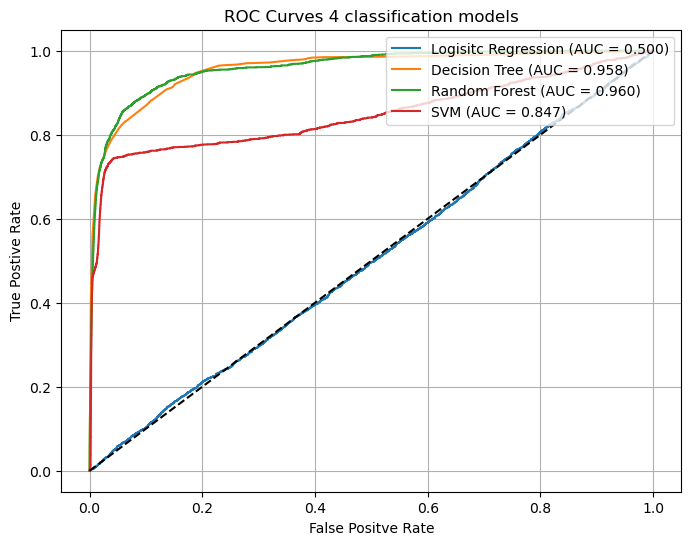

In [76]:
plt.figure(figsize=(8,6))
for probs, label in [
    (logit_prob2, "Logisitc Regression"),
    (tree_prob, "Decision Tree"),
    (rf_prob, "Random Forest"),
    (svm_prob, "SVM")
]:
  fpr, tpr, _ = roc_curve(y_test, probs)
  auc = roc_auc_score(y_test, probs)

  plt.plot(fpr, tpr, label = f"{label} (AUC = {auc:.3f})"
           )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positve Rate")
plt.ylabel("True Postive Rate")
plt.title("ROC Curves 4 classification models")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()
